In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("kc_house_data.csv")

print(df.head())

           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8        1680              0   

   yr_built  yr_renovated  zipcode      lat     lo

# Basic data understanding

In [8]:

print("Shape:", df.shape)

print(df.columns)

df.info()

print(df.describe())

print(df.dtypes)

Shape: (21613, 21)
Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             21613 non-null  int64         
 1   date           21613 non-null  datetime64[ns]
 2   price          21613 non-null  float64       
 3   bedrooms       21613 non-null  int64         
 4   bathrooms      21613 non-null  float64       
 5   sqft_living    21613 non-null  int64         
 6   sqft_lot       21613 non-null  int64         
 7   floors         21613 non-null  float64       
 8   waterfront     21613 non-null  int64         
 9   view      

# data cleaning

In [9]:

print(df.isnull().sum())

print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

df['date'] = pd.to_datetime(df['date'])

print(df.info())

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64
Duplicates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             21613 non-null  int64         
 1   date           21613 non-null  datetime64[ns]
 2   price          21613 non-null  float64       
 3   bedrooms       21613 non-null  int64         
 4   bathrooms      21613 non-null  float64       
 5   sqft_living    21613 non-null  int64         
 6   sqft_lot       21613 non-null  int64         
 7   f

# Univariate analysis

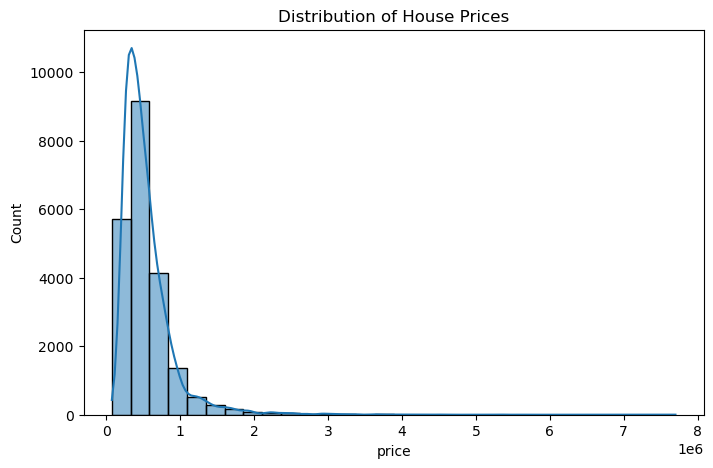

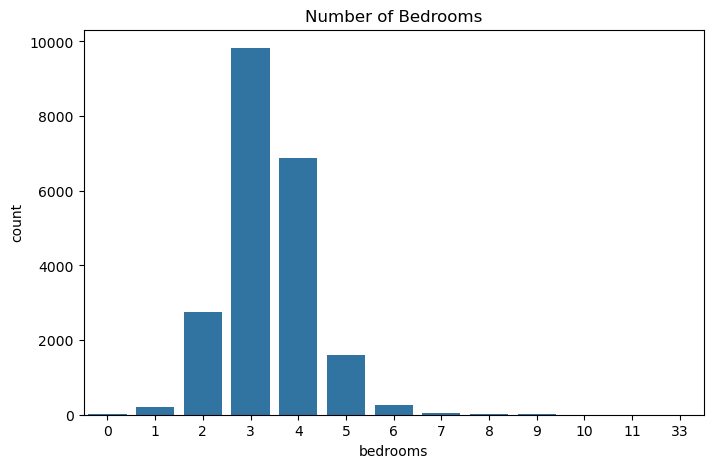

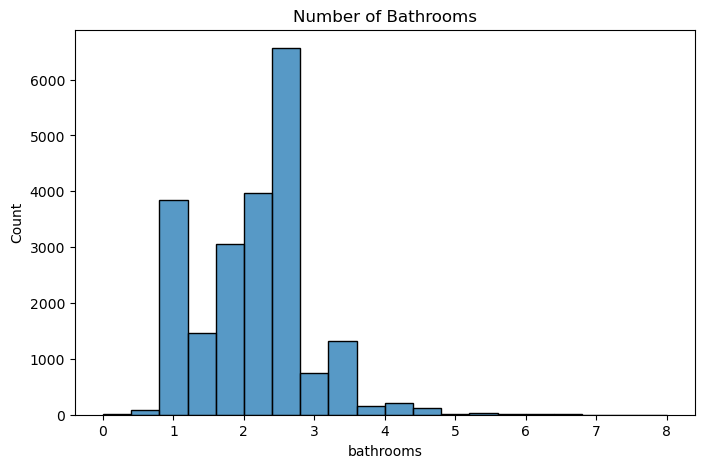

In [11]:

plt.figure(figsize=(8,5))
sns.histplot(df['price'], bins=30, kde=True)
plt.title("Distribution of House Prices")
plt.show()

plt.figure(figsize=(8,5))
sns.countplot(x='bedrooms', data=df)
plt.title("Number of Bedrooms")
plt.show()

plt.figure(figsize=(8,5))
sns.histplot(df['bathrooms'], bins=20)
plt.title("Number of Bathrooms")
plt.show()

# Bivariate analysis

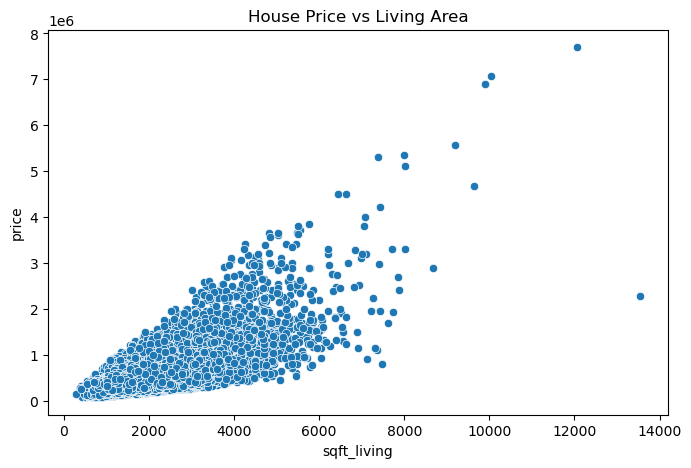

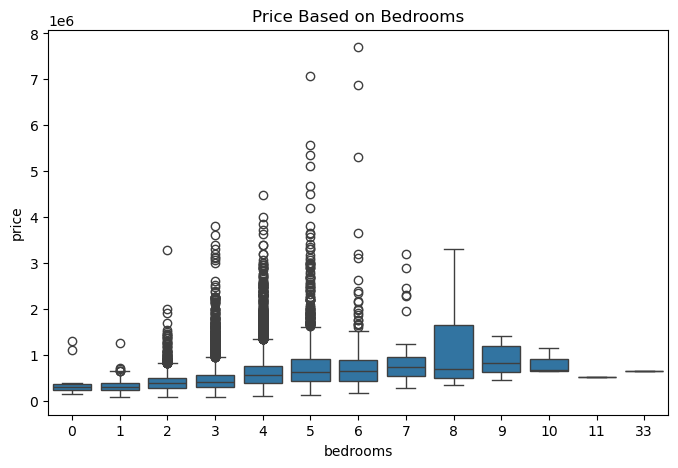

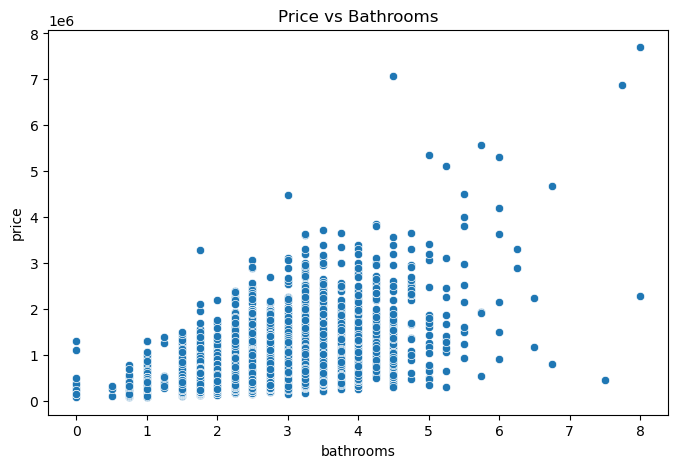

In [14]:

plt.figure(figsize=(8,5))
sns.scatterplot(x='sqft_living', y='price', data=df)
plt.title("House Price vs Living Area")
plt.show()

plt.figure(figsize=(8,5))
sns.boxplot(x='bedrooms', y='price', data=df)
plt.title("Price Based on Bedrooms")
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(x='bathrooms', y='price', data=df)
plt.title("Price vs Bathrooms")
plt.show()

# Correlation analysis

                     id     price  bedrooms  bathrooms  sqft_living  sqft_lot  \
id             1.000000 -0.016762  0.001286   0.005160    -0.012258 -0.132109   
price         -0.016762  1.000000  0.308350   0.525138     0.702035  0.089661   
bedrooms       0.001286  0.308350  1.000000   0.515884     0.576671  0.031703   
bathrooms      0.005160  0.525138  0.515884   1.000000     0.754665  0.087740   
sqft_living   -0.012258  0.702035  0.576671   0.754665     1.000000  0.172826   
sqft_lot      -0.132109  0.089661  0.031703   0.087740     0.172826  1.000000   
floors         0.018525  0.256794  0.175429   0.500653     0.353949 -0.005201   
waterfront    -0.002721  0.266369 -0.006582   0.063744     0.103818  0.021604   
view           0.011592  0.397293  0.079532   0.187737     0.284611  0.074710   
condition     -0.023783  0.036362  0.028472  -0.124982    -0.058753 -0.008958   
grade          0.008130  0.667434  0.356967   0.664983     0.762704  0.113621   
sqft_above    -0.010842  0.6

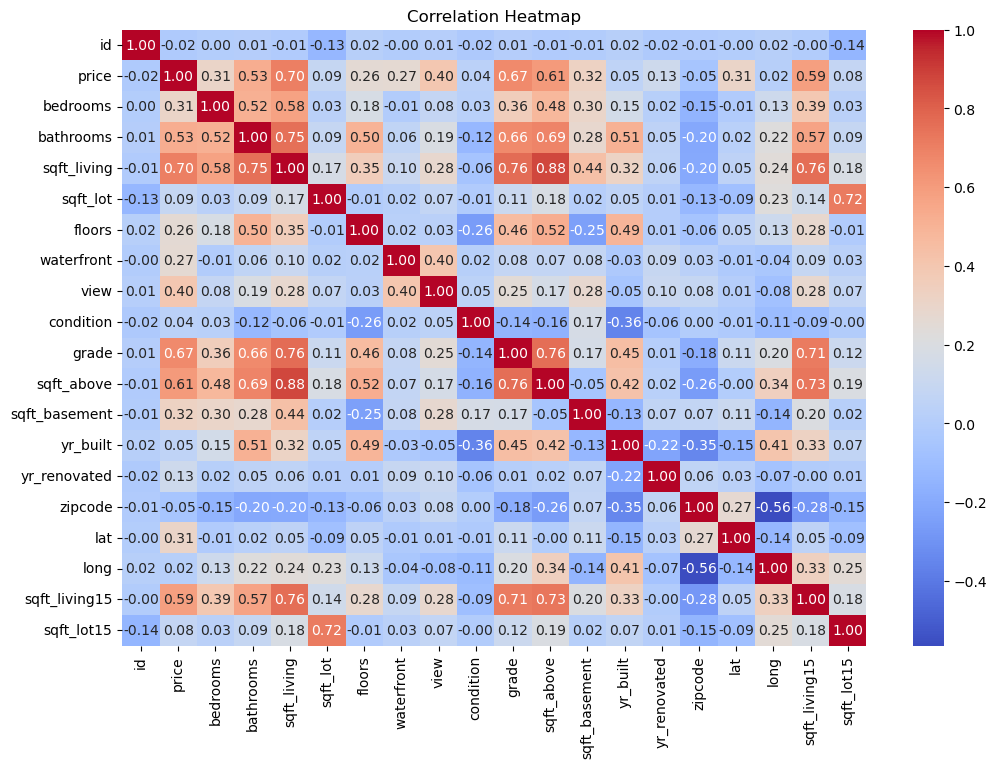

In [15]:

corr = df.select_dtypes(include=np.number).corr()

print(corr)

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

# Outlier detection

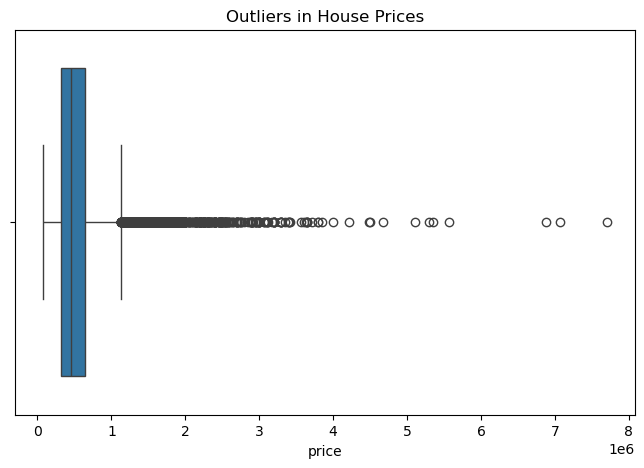

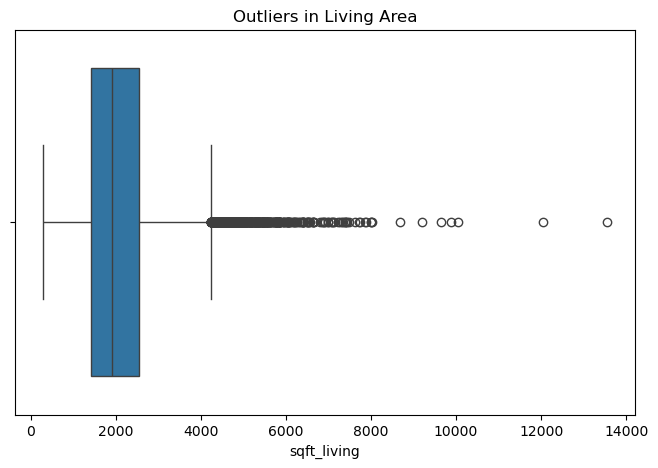

In [16]:

plt.figure(figsize=(8,5))
sns.boxplot(x=df['price'])
plt.title("Outliers in House Prices")
plt.show()

plt.figure(figsize=(8,5))
sns.boxplot(x=df['sqft_living'])
plt.title("Outliers in Living Area")
plt.show()

# Categorical analysis

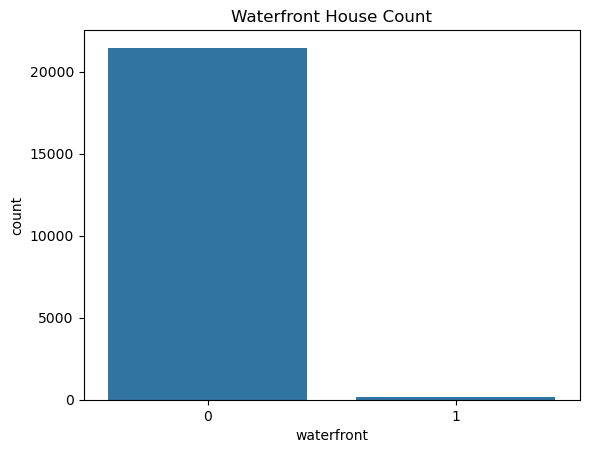

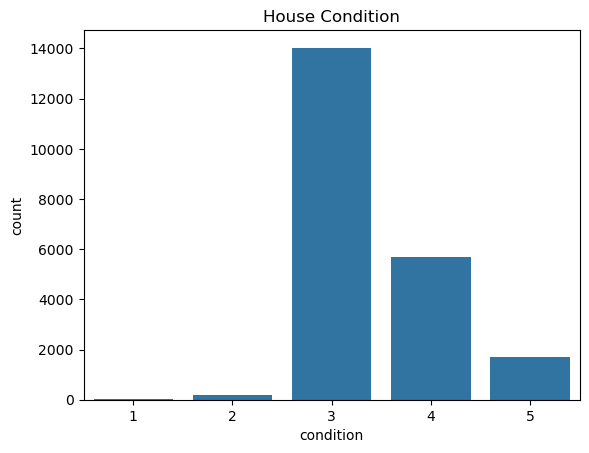

condition
1    334431.666667
2    327287.145349
3    542012.578148
4    521200.390033
5    612418.089359
Name: price, dtype: float64


In [17]:

sns.countplot(x='waterfront', data=df)
plt.title("Waterfront House Count")
plt.show()

sns.countplot(x='condition', data=df)
plt.title("House Condition")
plt.show()

print(df.groupby('condition')['price'].mean())

# Year-wise analysis

sale_year
2014    539181.428415
2015    541988.992264
Name: price, dtype: float64


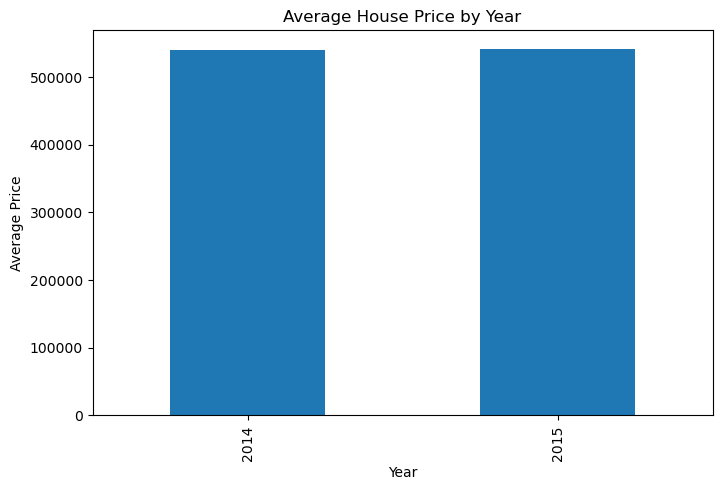

In [18]:

df['sale_year'] = df['date'].dt.year

year_price = df.groupby('sale_year')['price'].mean()

print(year_price)

year_price.plot(kind='bar', figsize=(8,5))
plt.title("Average House Price by Year")
plt.xlabel("Year")
plt.ylabel("Average Price")
plt.show()

# Final insights

In [19]:
print("Total Houses:", len(df))

print("Average Price:", df['price'].mean())

print("Highest Price:", df['price'].max())

print("Lowest Price:", df['price'].min())

print("Average Bedrooms:", df['bedrooms'].mean())

print("Average Bathrooms:", df['bathrooms'].mean())

print("Average Living Area:", df['sqft_living'].mean())

print("Correlation with Price:")
print(df.corr(numeric_only=True)['price'].sort_values(ascending=False))

Total Houses: 21613
Average Price: 540088.1417665294
Highest Price: 7700000.0
Lowest Price: 75000.0
Average Bedrooms: 3.37084162309721
Average Bathrooms: 2.1147573219821405
Average Living Area: 2079.8997362698374
Correlation with Price:
price            1.000000
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525138
view             0.397293
sqft_basement    0.323816
bedrooms         0.308350
lat              0.307003
waterfront       0.266369
floors           0.256794
yr_renovated     0.126434
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054012
condition        0.036362
long             0.021626
sale_year        0.003576
id              -0.016762
zipcode         -0.053203
Name: price, dtype: float64


# # EXPLORATORY DATA ANALYSIS (EDA) ON KING COUNTY HOUSE SALES DATASET

## 1. Introduction

Exploratory Data Analysis (EDA) is the process of examining and understanding a dataset using statistical methods and visualizations. It helps identify patterns, relationships, trends and unusual values in the data.

In this project, EDA is performed on the King County House Sales dataset to understand the factors that influence house prices. The dataset contains information about house prices, bedrooms, bathrooms, living area, location, condition and other features.

## 2. Objectives

- To understand the structure and characteristics of the dataset.
- To identify missing values and duplicate records.
- To analyze the distribution of house prices.
- To study relationships between house prices and other features.
- To identify outliers using boxplots.
- To visualize correlations between numerical variables.
- To derive meaningful insights from the dataset.

## 3. Dataset Description

The dataset used for this analysis is `kc_house_data.csv`.

It contains the following details:

| Description | Value |
|---|---:|
| Total records | 21,613 |
| Total columns | 21 |
| Target variable | Price |
| Missing values | 0 |
| Duplicate records | 0 |
| Data format | CSV |

Important attributes include:
- Price – Selling price of the house.
- Bedrooms – Number of bedrooms.
- Bathrooms – Number of bathrooms.
- Sqft_living – Interior living area.
- Sqft_lot – Total land area.
- Floors – Number of floors.
- Waterfront – Indicates whether the house has a waterfront view.
- Condition – Overall condition of the house.
- Grade – Overall construction and design quality.

## 4. Tools and Libraries Used

The following Python libraries were used:

1. **Pandas:** Used for loading, cleaning and analyzing data.
2. **NumPy:** Used for numerical calculations.
3. **Matplotlib:** Used for creating graphs and charts.
4. **Seaborn:** Used for statistical data visualization.

## 5. Methodology

### 5.1 Data Loading

The dataset was loaded using the Pandas `read_csv()` function. The `head()` function was used to display the first five records.

### 5.2 Data Understanding

Functions such as `shape`, `info()`, `describe()` and `dtypes` were used to understand the dimensions, data types and statistical properties of the dataset.

### 5.3 Data Cleaning

The dataset was checked for missing values and duplicate records.

- No missing values were found.
- No duplicate records were found.
- The date column was converted into datetime format.

### 5.4 Univariate Analysis

Univariate analysis was performed to study individual variables.

Histograms were used to analyze house prices and bathrooms. Count plots were used to understand the distribution of bedrooms.

### 5.5 Bivariate Analysis

Bivariate analysis was performed to understand relationships between two variables.

Scatter plots were used to study house prices against living area and bathrooms. Boxplots were used to compare prices based on the number of bedrooms.

### 5.6 Correlation Analysis

A correlation matrix and heatmap were created to identify relationships between numerical variables.

The analysis showed that living area and house grade have strong positive correlations with house prices.

### 5.7 Outlier Detection

Boxplots were used to identify unusual values in house prices, living area and lot area.

Outliers were identified but were not removed because they may represent genuine expensive or unusually large properties.

## 6. Analysis and Findings

### 6.1 House Price Analysis

- Average house price: approximately $540,088.
- Median house price: $450,000.
- Minimum house price: $75,000.
- Maximum house price: $7,700,000.

The average price is higher than the median, indicating that some expensive properties influence the overall average.

### 6.2 Bedroom Analysis

The dataset shows that most houses have three bedrooms, followed by four-bedroom houses.

The average number of bedrooms is approximately 3.37.

### 6.3 Living Area Analysis

The average living area is approximately 2,080 square feet.

Larger living areas generally show higher house prices, indicating a positive relationship between house size and selling price.

### 6.4 Bathroom Analysis

The average number of bathrooms is approximately 2.11.

Houses with more bathrooms generally tend to have higher prices.

### 6.5 Correlation Analysis

The strongest positive correlations with house price are:

| Feature | Correlation |
|---|---:|
| Living Area | 0.702 |
| Grade | 0.667 |
| Above Ground Area | 0.606 |
| Nearby Living Area | 0.585 |
| Bathrooms | 0.525 |

This indicates that living area and construction quality are important factors associated with house prices.

### 6.6 Outlier Analysis

Outliers were identified using boxplots and the Interquartile Range (IQR) method.

The analysis identified:
- 1,146 outliers in house prices.
- 572 outliers in living area.
- 2,425 outliers in lot area.

These values indicate the presence of unusually expensive houses and properties with large land areas.

### 6.7 House Condition Analysis

The average house price varies according to the condition of the property.

Houses with condition rating 5 have a higher average price than houses with lower condition ratings. However, house condition alone does not determine the selling price.

## 7. Key Insights

From the exploratory data analysis, the following insights were obtained:

1. The dataset contains 21,613 house records and 21 attributes.
2. There are no missing values or duplicate records.
3. The average house price is approximately $540,088.
4. Three-bedroom houses are the most common.
5. Living area has a strong positive relationship with house price.
6. House grade is another important feature associated with price.
7. Outliers are present in price, living area and lot area.
8. The average house price is higher than the median because of high-priced properties.

## 8. Conclusion

Exploratory Data Analysis was successfully performed on the King County House Sales dataset using Python.

Pandas and NumPy were used for data analysis, while Matplotlib and Seaborn were used for visualization.

The analysis revealed that living area, house grade and the number of bathrooms are important features associated with house prices. It also helped identify outliers and understand the distribution of different house characteristics.

Overall, EDA provided meaningful insights into the housing dataset and helped understand the factors that influence house prices. This analysis can be used as a foundation for further statistical analysis and house price prediction using Machine Learning.

## 9. Future Scope

The dataset can be further used to:

- Build a house price prediction model.
- Apply Linear Regression and other Machine Learning algorithms.
- Identify important features affecting house prices.
- Predict house prices based on property characteristics.
